Student: Mihhail Korasteljov

Subject: Energy Data Science ITS8080, autumn semester 2026

Solution for Assignement 5. Data cleaning 

**5. Data cleaning [9pt]**

Tips: Examine carefully which variables are required for your analysis.

5.1. Work with the PV_mod1, PV_mod2, and PV_mod3 variables.

5.1 (a) Identify missing values, outliers, or any inconsistencies in the provided dataset.





In [2]:
import pandas as pd

#Load dataset
df=pd.read_csv("266050_training.csv")
print("Dataset shape:", df.shape)
cols = ["pv_mod1", "pv_mod2", "pv_mod3"]

#Variables with units
print("Variables:")
print(df.columns.tolist())
#Five first rows
df.head()

#sort before time series analysis
df = df.sort_values("timestamp")
print("Monotonic after sorting:", df.index.is_monotonic_increasing)
print("Repeated local timestamps:", df.index.duplicated().sum())
display(df[cols].head(20))



Dataset shape: (8759, 18)
Variables:
['timestamp', 'pv_mod1', 'pv_mod2', 'pv_mod3', 'Demand', 'pv', 'Price', 'Temperature', 'Pressure (hPa)', 'Cloud_cover (%)', 'Cloud_cover_low (%)', 'Cloud_cover_mid (%)', 'Cloud_cover_high (%)', 'Wind_speed_10m (km/h)', 'Shortwave_radiation (W/m²)', 'direct_radiation (W/m²)', 'diffuse_radiation (W/m²)', 'direct_normal_irradiance (W/m²)']
Monotonic after sorting: True
Repeated local timestamps: 0


,pv_mod1,pv_mod2,pv_mod3
0,0.000,0.000,0.000
1,0.000,0.000,0.000
2,0.000,0.000,0.000
3,0.000,0.000,0.000
4,0.000,0.000,0.000
5,0.140,0.140,0.140
6,0.616,0.616,0.616
7,1.206,1.206,1.206
8,1.778,1.778,1.778
9,2.312,2.312,2.312


In [3]:
# Convert timestamps to Tallinn time
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["timestamp"] = df["timestamp"].dt.tz_convert("Europe/Tallinn")

# Set timestamp as index
df = df.set_index("timestamp").sort_index()

# Create expected hourly index
expected_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

# Identify missing timestamps
missing_timestamps = expected_index.difference(df.index)

print("Missing timestamps:", len(missing_timestamps))
print(missing_timestamps)

Missing timestamps: 1
DatetimeIndex(['2014-01-01 01:00:00+02:00'], dtype='datetime64[ns, Europe/Tallinn]', freq='h')


Reindexing inserts missing rows. Inserted row contains missing values.

In [5]:
# Insert missing timestamp as a new row
df = df.reindex(expected_index)
df.index.name = "timestamp"

print("Rows after reindexing:", len(df))
print("Remaining missing timestamps:",
      len(expected_index.difference(df.index)))

#columns with missing values
display(
    df[cols]
    .isna().sum().to_frame("NaN count")
)

Rows after reindexing: 8760
Remaining missing timestamps: 0


,NaN count
pv_mod1,438
pv_mod2,497
pv_mod3,511


Detect missing data

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df[cols].isna().sum(),
    "missing_percent": 100 * df[cols].isna().mean(),
})
missing_summary["missing_percent"] = missing_summary["missing_percent"].round(2)
display(missing_summary)

# Check negative values
print("Negative values:")
print((df[cols] < 0).sum())



,missing_count,missing_percent
pv_mod1,438,5.00
pv_mod2,497,5.67
pv_mod3,511,5.83


Negative values:
pv_mod1    0
pv_mod2    0
pv_mod3    0
dtype: int64


Outliers

In [7]:
# Visualize possible outliers
# Check outliers using IQR method
Q1 = df[cols].quantile(0.25)
Q3 = df[cols].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[cols] < Q1 - 1.5 * IQR) |
    (df[cols] > Q3 + 1.5 * IQR)
).sum()

print("Potential outliers:")
print(outliers)

Potential outliers:
pv_mod1    1146
pv_mod2    1148
pv_mod3    1217
dtype: int64


Result: The dataset contains missing values in all three PV modules: 5% in PV_mod1, 5.67% in PV_mod2, and 5.83% in PV_mod3. One missing timestamp was also identified. No negative PV measurements were found. IQR analysis was used to identify potential outliers. However, high PV generation during sunny hours may be physically valid, so statistical outliers should not automatically be removed.

5.1 (b) Identify the possible types of missing data mechanisms in each case and justify
your conclusion. A justification must reference evidence in the data, not only the
definition of the mechanism.



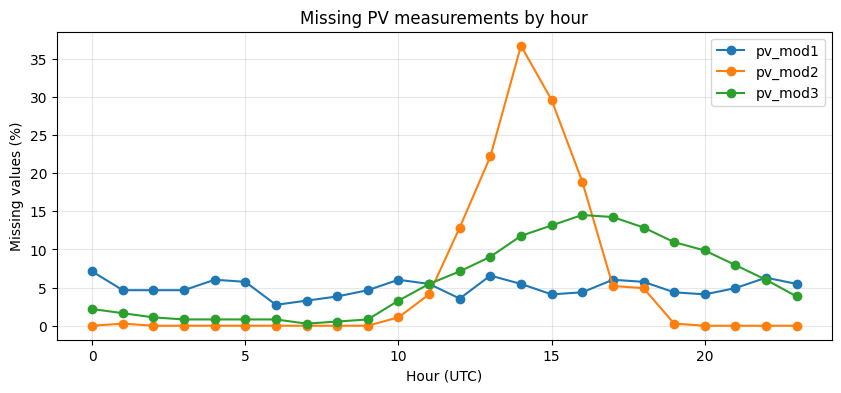


 pv_mod1
pv_mod1
False    7.485028
True     8.094050
Name: Temperature, dtype: float64

 pv_mod2
pv_mod2
False    7.378519
True     9.795968
Name: Temperature, dtype: float64

 pv_mod3
pv_mod3
False     6.579755
True     22.649216
Name: Temperature, dtype: float64


In [9]:
import matplotlib.pyplot as plt
# Missingness by hour
missing_hour = pd.DataFrame(index=range(24))

for col in cols:
    missing_hour[col] = (
        df[col].isna()
        .groupby(df.index.hour)
        .mean()
        .reindex(range(24)) * 100
    )

missing_hour.plot(
    figsize=(10, 4),
    marker="o",
    title="Missing PV measurements by hour"
)

plt.xlabel("Hour (UTC)")
plt.ylabel("Missing values (%)")
plt.grid(alpha=0.3)
plt.show()

# Compare temperature during observed and missing periods
for col in cols:
    print("\n", col)
    print(
        df.groupby(df[col].isna())["Temperature"]
        .mean()
    )

5.1 (c) Use at least three different methods to handle the missing data for the variable
mod1 based on deletion, univariate, and multivariate imputation techniques.

Three mechanisms are considered:

Method 1. MCAR	(Missing Completely at Random)	Random sensor or communication failure

Method 2. MAR	(Missing at Random, conditional on observed data)	Missingness related to hour or weather

Method 3. MNAR	(Missing Not at Random)	Sensor failure related to the unobserved PV output itself

In [12]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Method 1 MCAR: Implemented DELETION of rows with missing PV_mod1
df_delete = df.dropna(subset=["pv_mod1"]).copy()

# Method 2 MAR: Implemented UNIVARIANTE IMPUTATION. Replace missing values with the hourly median
df_median = df.copy()

hourly_median = df.groupby(df.index.hour)["pv_mod1"].median()

missing = df_median["pv_mod1"].isna()

df_median.loc[missing, "pv_mod1"] = (
    pd.Series(df_median.index.hour, index=df_median.index)
    .map(hourly_median)[missing]
)

# Method 3 MNAR: Implemented MULTIVARIANT RANDOM FOREST. Predict PV_mod1 from PV_mod2, PV_mod3 and time features
df_rf = df.copy()

features = ["pv_mod2", "pv_mod3", "Temperature"]

# Add calendar features
df_rf["hour"] = df_rf.index.hour
df_rf["month"] = df_rf.index.month

features += ["hour", "month"]

# Fill missing predictor values
X = df_rf[features].copy()
X = X.fillna(X.median())

observed = df_rf["pv_mod1"].notna()
missing = ~observed

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X.loc[observed],
    df_rf.loc[observed, "pv_mod1"]
)

predictions = model.predict(X.loc[missing])

# PV cannot be negative
df_rf.loc[missing, "pv_mod1"] = np.maximum(
    predictions, 0
)

# Compare numerical summaries
results = pd.DataFrame({
    "Original": df["pv_mod1"],
    "Deletion": df_delete["pv_mod1"],
    "Hourly median": df_median["pv_mod1"],
    "Random Forest": df_rf["pv_mod1"]
})

print(results.agg(["count", "mean", "var", "std"]).round(3))

       Original  Deletion  Hourly median  Random Forest
count  8322.000  8322.000       8760.000       8760.000
mean      0.658     0.658          0.655          0.659
var       1.223     1.223          1.193          1.225
std       1.106     1.106          1.092          1.107


Result: Three methods were selected for PV_mod1: deletion, hourly-median imputation, and multivariate Random Forest imputation. Deletion removes incomplete observations but reduces the available time series. Hourly-median imputation preserves the typical daily PV pattern but cannot capture individual weather conditions. Random Forest uses related PV modules and weather information to estimate missing values. Its predictions are constrained to non-negative values.

5.2. Compare the quality of each imputed data set using PV data.
(a) Include a numerical summary table (mean, variance, etc.).


In [ ]:

import numpy as np
import pandas as pd
from IPython.display import display

methods = {
    "Original": df["pv_mod1"],
    "Deletion": df_delete["pv_mod1"],
    "Hourly median": df_median["pv_mod1"],
    "Random Forest": df_rf["pv_mod1"]
}

summary = pd.DataFrame({
    name: {
        "Count": s.count(),
        "Missing": s.isna().sum(),
        "Mean": s.mean(),
        "Median": s.median(),
        "Variance": s.var(),
        "Std": s.std(),
        "Min": s.min(),
        "Max": s.max()
    }
    for name, s in methods.items()
}).T

display(summary.round(3))

,Count,Missing,Mean,Median,Variance,Std,Min,Max
Original,8322.0,438.0,0.658,0.0,1.223,1.106,0.0,4.969
Deletion,8322.0,0.0,0.658,0.0,1.223,1.106,0.0,4.969
Hourly median,8760.0,0.0,0.655,0.0,1.193,1.092,0.0,4.969
Random Forest,8760.0,0.0,0.659,0.0,1.225,1.107,0.0,4.969


Test imputation accuracy
This follows the practical_06 masking experiment. We temporarily hide 10% of observed pv_mod1 values and evaluate how accurately each method reconstructs them.

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor

rng = np.random.default_rng(42)

# Select known PV_mod1 observations
known = df.index[df["pv_mod1"].notna()]

# Randomly hide 10%
test_idx = rng.choice(
    known,
    size=int(len(known) * 0.10),
    replace=False
)

test_idx = pd.DatetimeIndex(test_idx)

# Preserve true values
y_true = df.loc[test_idx, "pv_mod1"].copy()

# Create artificial missing values
test_df = df.copy()
test_df.loc[test_idx, "pv_mod1"] = np.nan

# Method- Hourly median
hourly = test_df.groupby(
    test_df.index.hour
)["pv_mod1"].median()

hour_map = pd.Series(
    test_df.index.hour,
    index=test_df.index
).map(hourly)

pred_median = test_df["pv_mod1"].fillna(hour_map).loc[test_idx]

# Method 2 -Random Forest
X = test_df[["pv_mod2", "pv_mod3", "Temperature"]].copy()

X["hour"] = X.index.hour
X["month"] = X.index.month

# Fit predictor imputation on training observations only
train_mask = test_df["pv_mod1"].notna()

predictor_medians = X.loc[train_mask].median()
X = X.fillna(predictor_medians)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X.loc[train_mask],
    test_df.loc[train_mask, "pv_mod1"]
)

pred_rf = np.maximum(
    model.predict(X.loc[test_idx]),
    0
)

# Compare reconstruction errors
accuracy = pd.DataFrame({
    "Method": ["Hourly median", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_true, pred_median),
        mean_absolute_error(y_true, pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_true, pred_median)),
        np.sqrt(mean_squared_error(y_true, pred_rf))
    ]
})

display(accuracy.round(4))

,Method,MAE,RMSE
0,Hourly median,0.4790,0.8153
1,Random Forest,0.0102,0.0946


Visualize comparision

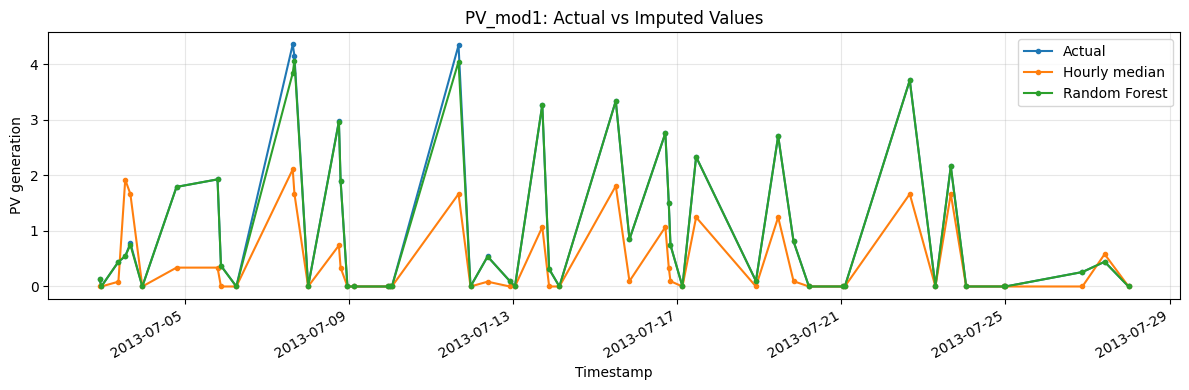

In [17]:
import matplotlib.pyplot as plt

# Compare original and reconstructed values
comparison = pd.DataFrame({
    "Actual": y_true,
    "Hourly median": pred_median,
    "Random Forest": pred_rf
}).sort_index()

# Show first 50 test observations
sample = comparison.iloc[:50]

ax = sample.plot(
    figsize=(12, 4),
    marker="o",
    markersize=3,
    title="PV_mod1: Actual vs Imputed Values"
)

ax.set_xlabel("Timestamp")
ax.set_ylabel("PV generation")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

5.2 RESULTS:Comparison of Imputation Methods

Three methods were compared: deletion, hourly median, and Random Forest.

Deletion reduces the number of observations. Hourly median preserves the typical daily PV pattern but ignores weather changes. Random Forest uses other PV modules and weather data to estimate missing values.

The methods were compared using mean, variance, MAE, and RMSE. Lower MAE and RMSE indicate better imputation accuracy. The best method should also preserve realistic PV generation values.

5.3. Visualise before and after for a few representative time instances.


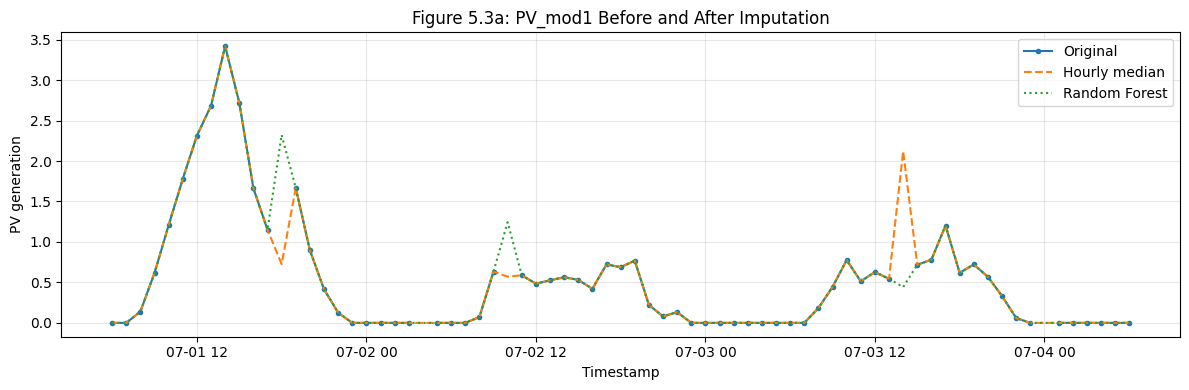

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Find a 3-day window with missing PV_mod1 values
missing_times = df.index[df["pv_mod1"].isna()]
start = missing_times[0] - pd.Timedelta(hours=12)
end = start + pd.Timedelta(days=3)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    df.loc[start:end].index,
    df.loc[start:end, "pv_mod1"],
    label="Original",
    marker="o", markersize=3
)

ax.plot(
    df_median.loc[start:end].index,
    df_median.loc[start:end, "pv_mod1"],
    label="Hourly median",
    linestyle="--"
)

ax.plot(
    df_rf.loc[start:end].index,
    df_rf.loc[start:end, "pv_mod1"],
    label="Random Forest",
    linestyle=":"
)

ax.set_title("Figure 5.3a: PV_mod1 Before and After Imputation")
ax.set_xlabel("Timestamp")
ax.set_ylabel("PV generation")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

RESULTS 5.3: The figure compares PV generation before and after imputation. Both methods fill missing values, while Random Forest uses additional information from other PV modules and weather data.

5.4. For at least one of your imputation methods, find a timestamp where it produces a
physically impossible value. Show it, if any.



In [19]:
# Check physically impossible PV values

import pandas as pd
import numpy as np

missing = df["pv_mod1"].isna()

# Check negative and above-capacity values
# Use 5 kW as the assumed PV capacity
pv_max = 5.0

for name, data in {
    "Hourly median": df_median,
    "Random Forest": df_rf
}.items():

    values = data.loc[missing, "pv_mod1"]

    impossible = (
        (values < 0) |
        (values > pv_max)
    )

    print(f"\n{name}")
    print("Impossible values:", impossible.sum())

    if impossible.any():
        print(values[impossible].head())
    else:
        print("No negative or above-capacity values found.")


Hourly median
Impossible values: 0
No negative or above-capacity values found.

Random Forest
Impossible values: 0
No negative or above-capacity values found.


In [ ]:
# Check night time generation
# Find imputed positive values when original PV was zero

for name, data in {
    "Hourly median": df_median,
    "Random Forest": df_rf
}.items():

    suspicious = (
        missing &
        (df["pv"] == 0) &
        (data["pv_mod1"] > 0)
    )

    print(f"\n{name}")
    print("Suspicious values:", suspicious.sum())

    if suspicious.any():
        t = df.index[suspicious][0]

        print("Timestamp:", t)
        print("Original PV:", df.loc[t, "pv"])
        print("Imputed PV:", data.loc[t, "pv_mod1"])


Hourly median
Suspicious values: 33
Timestamp: 2013-10-09 09:00:00+03:00
Original PV: 0.0
Imputed PV: 0.083

Random Forest
Suspicious values: 0


5.4 RESULTS:

I checked the imputed PV values for negative generation, values above the assumed 5 kW capacity, and positive generation when the original PV was zero.

Negative values and generation above system capacity would be physically impossible. Positive values when the original PV was zero require further investigation, especially during nighttime.


5.5. State, for each of your three methods, whether it uses information from after the
imputed timestamp. Which of them could not be applied in a live system that must
clean data as it arrives, and what would you use instead?

ANSWER fo 5.5:

Deletion does not use future data, but it removes observations.

Hourly median uses future information if calculated from the entire dataset. In a live system, I would calculate medians using only historical data.

Random Forest also uses future information if trained on the full dataset. For live operation, I would train it on historical observations and use only predictors available at the time of imputation.

Therefore, both imputation methods need adjustments to avoid future data leakage in a live system.